# Catching card fraud, priced in euros

Stephen tAMBI

A card issuer wants to stop fraud without blocking honest customers. This notebook trains models on the public ULB credit card fraud dataset, tests them on later payments than they learned from, and prices every alert threshold in euros.

Data: [Credit Card Fraud Detection](https://www.kaggle.com/datasets/mlg-ulb/creditcard), Machine Learning Group, Université Libre de Bruxelles. Place `creditcard.csv` in `../data/`.

In [1]:
import pandas as pd, numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import average_precision_score, roc_auc_score

df = pd.read_csv('../data/creditcard.csv')
print(df.shape)
print(f"Fraud rate: {df.Class.mean():.3%}, fraud total: €{df.loc[df.Class==1,'Amount'].sum():,.0f}")

(284807, 31)
Fraud rate: 0.173%, fraud total: €60,128


## Why accuracy is the wrong score
A model that never flags fraud is already this accurate:

In [2]:
print(f'Accuracy of always saying "not fraud": {1 - df.Class.mean():.2%}')

Accuracy of always saying "not fraud": 99.83%


## Time-based split
Train on the first 70% of the time window, test on the last 30%, the way a bank would use the model on future payments.

In [3]:
cut = df.Time.quantile(0.70)
train, test = df[df.Time <= cut], df[df.Time > cut]
features = [c for c in df.columns if c != 'Class']
Xtr, ytr, Xte, yte = train[features], train.Class, test[features], test.Class
print(len(train), 'train,', len(test), 'test,', yte.sum(), 'test frauds worth €%.2f' % test.loc[test.Class==1,'Amount'].sum())

199368 train, 85439 test, 108 test frauds worth €14566.58


## Models
All three are weighted for the rare fraud class. PR-AUC is the main score.

In [4]:
models = {
    'Logistic regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight='balanced')),
    'Gradient boosting': HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_leaf_nodes=31, class_weight='balanced', random_state=42),
    'Random forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=2, class_weight='balanced_subsample', n_jobs=-1, random_state=42),
}
scores = {}
for name, m in models.items():
    m.fit(Xtr, ytr)
    scores[name] = m.predict_proba(Xte)[:, 1]
pd.DataFrame({n: {'PR-AUC': average_precision_score(yte, p), 'ROC-AUC': roc_auc_score(yte, p)} for n, p in scores.items()}).T.round(3)

,PR-AUC,ROC-AUC
Logistic regression,0.768,0.980
Gradient boosting,0.782,0.959
Random forest,0.820,0.968


## Price every threshold
A caught fraud saves its amount, a missed one loses it, every alert costs a review (€5 here).

In [5]:
p, y, amt = scores['Random forest'], yte.to_numpy(), test.Amount.to_numpy()
rows = []
for t in np.round(np.arange(0.01, 1.0001, 0.01), 2):
    f = p >= t
    rows.append({'threshold': t, 'flagged': f.sum(), 'caught': (f & (y==1)).sum(), 'false_alarms': (f & (y==0)).sum(),
                 'caught_eur': amt[f & (y==1)].sum(), 'missed_eur': amt[~f & (y==1)].sum()})
curve = pd.DataFrame(rows)
for cost in (5, 15, 30):
    curve[f'net_{cost}'] = curve.caught_eur - cost * curve.flagged
curve.loc[curve.threshold.isin([0.1, 0.18, 0.3, 0.5, 0.7])].round(0)

,threshold,flagged,caught,false_alarms,caught_eur,missed_eur,net_5,net_15,net_30
9,0.0,107,85,22,12030.0,2536.0,11495.0,10425.0,8820.0
17,0.0,96,84,12,12028.0,2539.0,11548.0,10588.0,9148.0
29,0.0,88,83,5,11791.0,2776.0,11351.0,10471.0,9151.0
49,0.0,77,76,1,9915.0,4652.0,9530.0,8760.0,7605.0
69,1.0,60,60,0,5058.0,9508.0,4758.0,4158.0,3258.0


In [6]:
best = curve.loc[curve.net_5.idxmax()]
print(f"Best threshold at €5 per review: {best.threshold:.2f}")
print(f"Stops €{best.caught_eur:,.0f} of €{amt[y==1].sum():,.0f} fraud ({best.caught_eur/amt[y==1].sum():.0%}), {best.false_alarms:.0f} false alarms, net €{best.net_5:,.0f}")

Best threshold at €5 per review: 0.18
Stops €12,028 of €14,567 fraud (83%), 12 false alarms, net €11,548


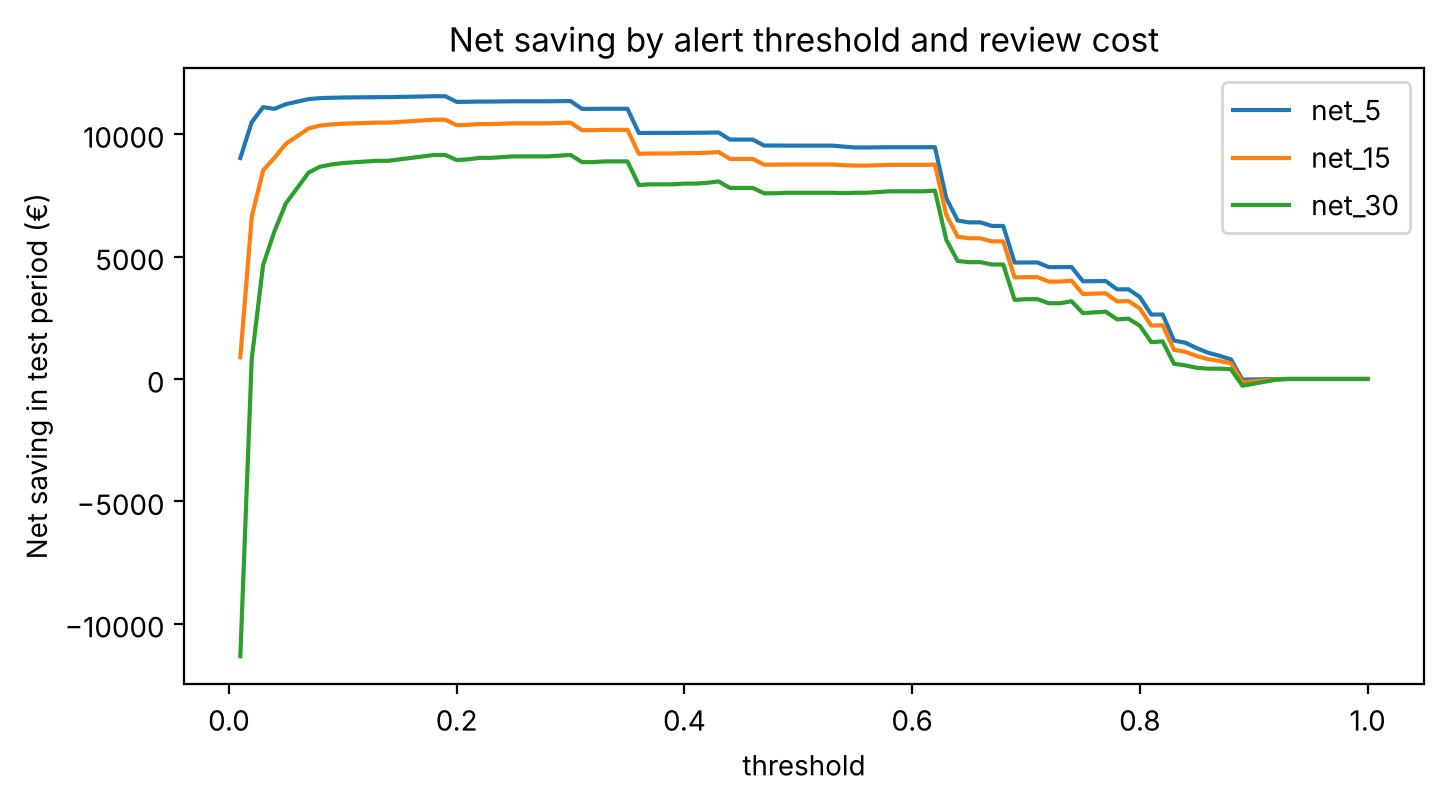

In [7]:
import matplotlib.pyplot as plt
ax = curve.plot(x='threshold', y=['net_5', 'net_15', 'net_30'], figsize=(8, 4))
ax.set_ylabel('Net saving in test period (€)'); ax.set_title('Net saving by alert threshold and review cost'); plt.show()

## Recommendations
1. **Two tiers:** decline automatically above 0.50, send 0.18–0.50 to an analyst or a 3-D Secure check.
2. **Set the threshold by cost:** agree the review cost first, then let the curve pick the threshold.
3. **Cover the blind spot:** add simple rules (payment velocity, new merchant) for the frauds the model misses.
4. **Retrain and monitor:** track the share of alerts that are fraud; a falling share is the early warning.

The interactive version is at https://stambi292.github.io/fraud-detection/